In [3]:
pip install pandas numpy matplotlib seaborn scikit-learn nltk ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import re
import nltk

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
import urllib.request
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = urllib.request.urlopen(url)
zip_file = zipfile.ZipFile(io.BytesIO(response.read()))

with zip_file.open("SMSSpamCollection") as file:
    df = pd.read_csv(
        file,
        sep='\t',
        header=None,
        names=['label', 'message'],
        encoding='utf-8'
    )

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [8]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())

df.info()

Dataset Shape: (5572, 2)

Column Names: ['label', 'message']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("\nDataset Shape After Removing Duplicates:", df.shape)

Missing Values:
label      0
message    0
dtype: int64

Duplicate Records: 403

Dataset Shape After Removing Duplicates: (5169, 2)


Message Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


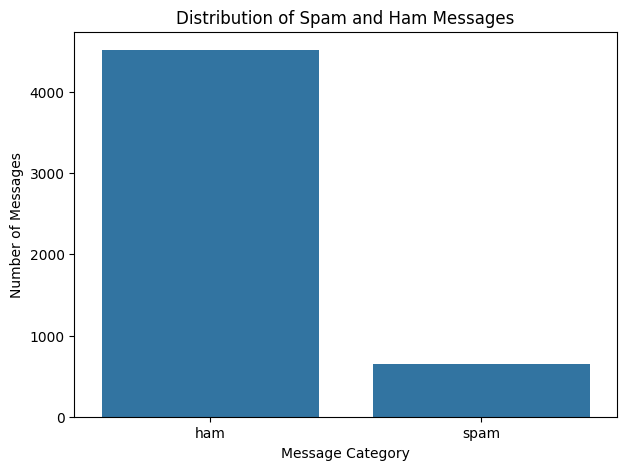

In [11]:
print("Message Distribution:")
print(df['label'].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label')

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [12]:
percentage = df['label'].value_counts(normalize=True) * 100

print("Percentage Distribution:")
print(percentage.round(2))

Percentage Distribution:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


In [13]:
nltk.download('punkt')
nltk.download('punkt_tab')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [14]:
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

stemmer = PorterStemmer()

def preprocess_text(text):

    text = text.lower()

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    words = word_tokenize(text)

    words = [stemmer.stem(word) for word in words]

    return ' '.join(words)

print("Text preprocessing function created successfully!")

Text preprocessing function created successfully!


In [15]:
df['clean_message'] = df['message'].apply(preprocess_text)

df[['message', 'clean_message']].head(10)

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazi avail onli in bugi...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri in a wkli comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so earli hor u c alreadi then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goe to usf he live around ...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darl it been week now and no...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request mell mell oru minnaminungi...
8,WINNER!! As a valued network customer you have...,winner as a valu network custom you have been ...
9,Had your mobile 11 months or more? U R entitle...,had your mobil month or more u r entitl to upd...


In [16]:
df['label_num'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

X = df['clean_message']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Train-test split completed successfully!")

Training samples: 4135
Testing samples: 1034
Train-test split completed successfully!


In [17]:
tfidf = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Feature Extraction Completed!")

print("Training Data Shape:", X_train_tfidf.shape)
print("Testing Data Shape:", X_test_tfidf.shape)

TF-IDF Feature Extraction Completed!
Training Data Shape: (4135, 3000)
Testing Data Shape: (1034, 3000)


In [18]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes Model Trained Successfully!")

Multinomial Naive Bayes Model Trained Successfully!


In [19]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [20]:
def evaluate_model(y_true, y_pred, model_name):

    print("\n", model_name)
    print("-" * 40)

    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1 Score:", round(f1_score(y_true, y_pred, zero_division=0), 4))


evaluate_model(y_test, y_pred_nb, "Multinomial Naive Bayes")

evaluate_model(y_test, y_pred_lr, "Logistic Regression")


 Multinomial Naive Bayes
----------------------------------------
Accuracy: 0.9691
Precision: 0.9901
Recall: 0.7634
F1 Score: 0.8621

 Logistic Regression
----------------------------------------
Accuracy: 0.9681
Precision: 0.9804
Recall: 0.7634
F1 Score: 0.8584


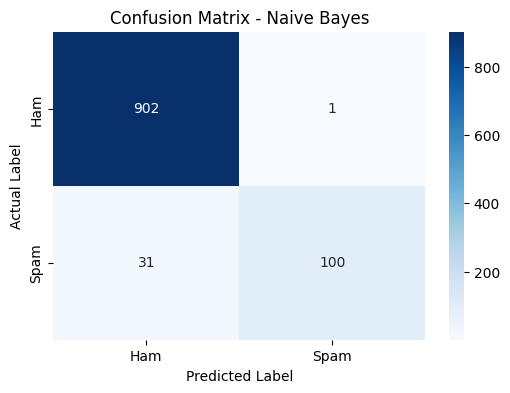

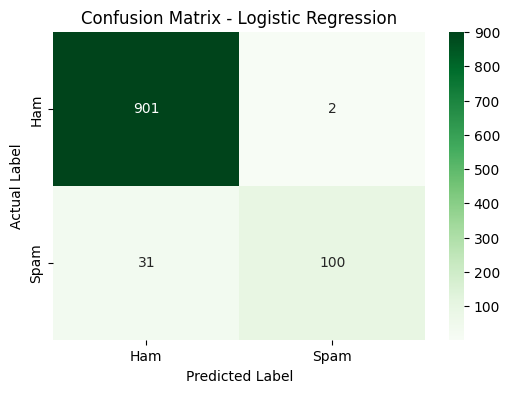

In [21]:
cm_nb = confusion_matrix(y_test, y_pred_nb)
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [22]:
print("NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Ham', 'Spam']
))

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Ham', 'Spam']
))

NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       0.99      0.76      0.86       131

    accuracy                           0.97      1034
   macro avg       0.98      0.88      0.92      1034
weighted avg       0.97      0.97      0.97      1034

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       0.98      0.76      0.86       131

    accuracy                           0.97      1034
   macro avg       0.97      0.88      0.92      1034
weighted avg       0.97      0.97      0.97      1034



In [23]:
results = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr)
    ],

    'Precision': [
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_lr)
    ],

    'Recall': [
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_lr)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_lr)
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.9691,0.9901,0.7634,0.8621
1,Logistic Regression,0.9681,0.9804,0.7634,0.8584


In [24]:
!pip install wordcloud

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


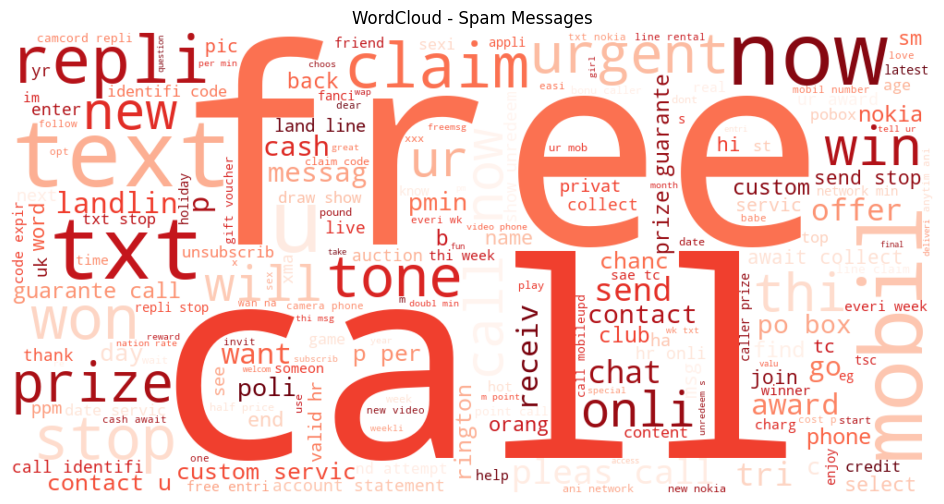

In [27]:
from wordcloud import WordCloud

spam_text = " ".join(
    df[df['label'] == 'spam']['clean_message']
)

spam_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='Reds'
).generate(spam_text)

plt.figure(figsize=(12, 6))
plt.imshow(spam_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud - Spam Messages")
plt.show()

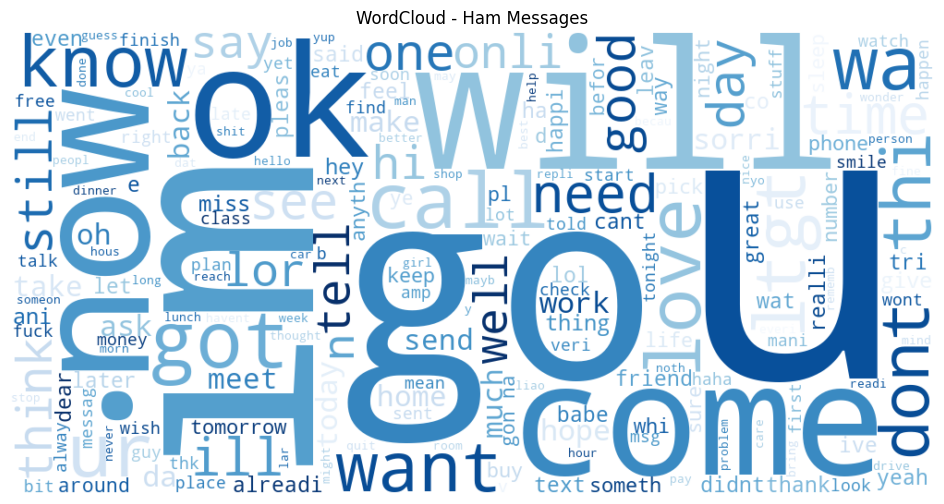

In [28]:
ham_text = " ".join(
    df[df['label'] == 'ham']['clean_message']
)

ham_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='Blues'
).generate(ham_text)

plt.figure(figsize=(12, 6))
plt.imshow(ham_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud - Ham Messages")
plt.show()

In [29]:
new_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting tomorrow?",
    "URGENT! You have won a cash reward. Call now!",
    "I will reach home in 10 minutes."
]

cleaned_messages = [
    preprocess_text(msg) for msg in new_messages
]

new_tfidf = tfidf.transform(cleaned_messages)

predictions = nb_model.predict(new_tfidf)

for message, prediction in zip(new_messages, predictions):
    result = "SPAM" if prediction == 1 else "HAM"
    print("Message:", message)
    print("Prediction:", result)
    print("-" * 60)

Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
------------------------------------------------------------
Message: Hey, are we meeting tomorrow?
Prediction: HAM
------------------------------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
------------------------------------------------------------
Message: I will reach home in 10 minutes.
Prediction: HAM
------------------------------------------------------------
